# SMS Spam Assignment — Text Preprocessing & Vectorization
Applying the complete text preprocessing pipeline (**Lowercasing, Punctuation Removal, Tokenization, Stopwords Removal, and Lemmatization**) followed by **Count Vectorization, N-Grams, and TF-IDF** on `spam.csv`, showing the text before and after each step.

## 1. Import Libraries & Setup

In [1]:
# Suppress warnings and import required packages
import warnings
warnings.filterwarnings('ignore')

import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

pd.set_option('display.max_colwidth', 200)

## 2. Load & Explore Dataset

In [2]:
# Load spam.csv, drop unused empty columns, and rename target/text columns
SMS_SH_df = pd.read_csv('spam.csv', encoding='latin-1')[['v1', 'v2']]
SMS_SH_df.columns = ['label', 'body_text']
SMS_SH_df.head()

,label,body_text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [3]:
# Check dataset shape, data types, missing values, and descriptive summary
print('Dataset Shape:', SMS_SH_df.shape)
print('\nMissing Values:\n', SMS_SH_df.isnull().sum())
SMS_SH_df.describe()

Dataset Shape: (5572, 2)

Missing Values:
 label        0
body_text    0
dtype: int64


,label,body_text
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


,Count,Percentage (%)
label,,
ham,4825,86.59
spam,747,13.41


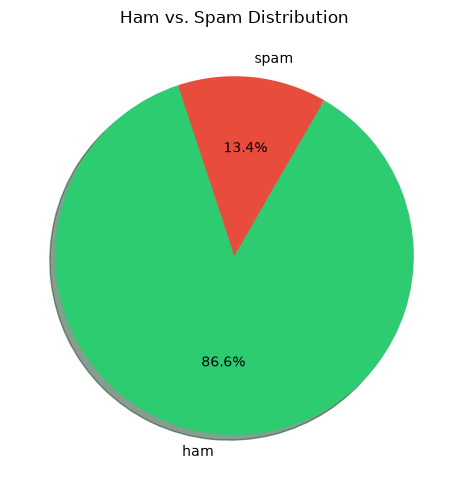

In [4]:
# Inspect class distribution (counts and percentages)
counts = SMS_SH_df['label'].value_counts()
props = SMS_SH_df['label'].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({'Count': counts, 'Percentage (%)': props.round(2)})
display(dist_df)

# Plot class distribution
fig, ax = plt.subplots(figsize=(5, 5))
colors = ['#2ecc71', '#e74c3c']
counts.plot.pie(autopct='%1.1f%%', shadow=True, startangle=60, counterclock=False, colors=colors, ax=ax)
ax.set_ylabel('')
ax.set_title('Ham vs. Spam Distribution')
plt.tight_layout()
plt.show()

In [5]:
# Create working copy of the dataset
df = SMS_SH_df.copy()

## 3. Text Preprocessing
Each step uses **list comprehension** and `.apply(lambda x: ...)` and displays the text **before and after**.

### 3.1 Lowercasing & Removing Punctuation

In [6]:
# Convert characters to lowercase and remove punctuation using list comprehension
def remove_punct(text):
    text_nopunct = ''.join([char.lower() for char in text if char not in string.punctuation])
    return text_nopunct

df['body_text_nopunc'] = df['body_text'].apply(lambda x: remove_punct(x))

# Show text BEFORE and AFTER lowercasing & punctuation removal
df[['body_text', 'body_text_nopunc']].head()

,body_text,body_text_nopunc
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry questionstd txt ratetcs apply 08452810075over18s
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives around here though",nah i dont think he goes to usf he lives around here though


### 3.2 Tokenization

In [7]:
# Split cleaned text into word tokens using NLTK word_tokenize
def tokenize(text):
    tokens = word_tokenize(text)
    return tokens

df['body_text_tokenized'] = df['body_text_nopunc'].apply(lambda x: tokenize(x))

# Show text BEFORE and AFTER tokenization
df[['body_text_nopunc', 'body_text_tokenized']].head()

,body_text_nopunc,body_text_tokenized
0,go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat,"[go, until, jurong, point, crazy, available, only, in, bugis, n, great, world, la, e, buffet, cine, there, got, amore, wat]"
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry questionstd txt ratetcs apply 08452810075over18s,"[free, entry, in, 2, a, wkly, comp, to, win, fa, cup, final, tkts, 21st, may, 2005, text, fa, to, 87121, to, receive, entry, questionstd, txt, ratetcs, apply, 08452810075over18s]"
3,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, then, say]"
4,nah i dont think he goes to usf he lives around here though,"[nah, i, dont, think, he, goes, to, usf, he, lives, around, here, though]"


### 3.3 Removing Stopwords

In [8]:
# Remove English stopwords using list comprehension
stopwords_En = set(stopwords.words('english'))

def remove_stopwords(tokenized_list):
    text = [word for word in tokenized_list if word not in stopwords_En]
    return text

df['body_text_nostop'] = df['body_text_tokenized'].apply(lambda x: remove_stopwords(x))

# Show tokens BEFORE and AFTER stopwords removal
df[['body_text_tokenized', 'body_text_nostop']].head()

,body_text_tokenized,body_text_nostop
0,"[go, until, jurong, point, crazy, available, only, in, bugis, n, great, world, la, e, buffet, cine, there, got, amore, wat]","[go, jurong, point, crazy, available, bugis, n, great, world, la, e, buffet, cine, got, amore, wat]"
1,"[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]"
2,"[free, entry, in, 2, a, wkly, comp, to, win, fa, cup, final, tkts, 21st, may, 2005, text, fa, to, 87121, to, receive, entry, questionstd, txt, ratetcs, apply, 08452810075over18s]","[free, entry, 2, wkly, comp, win, fa, cup, final, tkts, 21st, may, 2005, text, fa, 87121, receive, entry, questionstd, txt, ratetcs, apply, 08452810075over18s]"
3,"[u, dun, say, so, early, hor, u, c, already, then, say]","[u, dun, say, early, hor, u, c, already, say]"
4,"[nah, i, dont, think, he, goes, to, usf, he, lives, around, here, though]","[nah, dont, think, goes, usf, lives, around, though]"


### 3.4 Lemmatization
Using `WordNetLemmatizer` instead of stemming so inflected words are reduced to valid dictionary lemmas.

In [9]:
# Lemmatize tokens using WordNetLemmatizer and list comprehension
wn = nltk.WordNetLemmatizer()

def lemmatizing(tokenized_text):
    text = [wn.lemmatize(word) for word in tokenized_text]
    return text

df['body_text_lemmatized'] = df['body_text_nostop'].apply(lambda x: lemmatizing(x))

# Show tokens BEFORE and AFTER lemmatization
df[['body_text_nostop', 'body_text_lemmatized']].head()

,body_text_nostop,body_text_lemmatized
0,"[go, jurong, point, crazy, available, bugis, n, great, world, la, e, buffet, cine, got, amore, wat]","[go, jurong, point, crazy, available, bugis, n, great, world, la, e, buffet, cine, got, amore, wat]"
1,"[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]"
2,"[free, entry, 2, wkly, comp, win, fa, cup, final, tkts, 21st, may, 2005, text, fa, 87121, receive, entry, questionstd, txt, ratetcs, apply, 08452810075over18s]","[free, entry, 2, wkly, comp, win, fa, cup, final, tkts, 21st, may, 2005, text, fa, 87121, receive, entry, questionstd, txt, ratetcs, apply, 08452810075over18s]"
3,"[u, dun, say, early, hor, u, c, already, say]","[u, dun, say, early, hor, u, c, already, say]"
4,"[nah, dont, think, goes, usf, lives, around, though]","[nah, dont, think, go, usf, life, around, though]"


### 3.5 Unified Preprocessing Function (`clean_text`)

In [10]:
# Combine punctuation removal, lowercasing, tokenization, stopword removal, and lemmatization
def clean_text(text):
    text = ''.join([word.lower() for word in text if word not in string.punctuation])
    tokens = word_tokenize(text)
    text = ' '.join([wn.lemmatize(word) for word in tokens if word not in stopwords_En])
    return text

df = df[['label', 'body_text']].copy()
df['cleaned_text'] = df['body_text'].apply(lambda x: clean_text(x))

# Compare original text (BEFORE) vs. final preprocessed text (AFTER)
df[['label', 'body_text', 'cleaned_text']].head(10)

,label,body_text,cleaned_text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go jurong point crazy available bugis n great world la e buffet cine got amore wat
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entry 2 wkly comp win fa cup final tkts 21st may 2005 text fa 87121 receive entry questionstd txt ratetcs apply 08452810075over18s
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives around here though",nah dont think go usf life around though
5,spam,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv",freemsg hey darling 3 week word back id like fun still tb ok xxx std chgs send å£150 rcv
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.,even brother like speak treat like aid patent
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune,per request melle melle oru minnaminunginte nurungu vettam set callertune caller press 9 copy friend callertune
8,spam,WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.,winner valued network customer selected receivea å£900 prize reward claim call 09061701461 claim code kl341 valid 12 hour
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030,mobile 11 month u r entitled update latest colour mobile camera free call mobile update co free 08002986030


## 4. Vectorizing Text Data
Converting `cleaned_text` into numerical feature matrices using **Count Vectorization**, **N-Grams**, and **TF-IDF**.

### 4.1 Count Vectorization

In [11]:
# Apply CountVectorizer on cleaned_text
vectorizer = CountVectorizer()
features_CountVec = vectorizer.fit_transform(df['cleaned_text'])

print('Text BEFORE Count Vectorization (first 5 rows):')
display(df[['body_text', 'cleaned_text']].head())

print('Count Vectorizer Matrix Shape:', features_CountVec.shape)
print('Sparse Matrix Preview (first 2 rows):\n', features_CountVec[:2])

# Display DataFrame preview for the first 5 messages (showing active non-zero features)
cv_sample_df = pd.DataFrame(features_CountVec[:5].toarray(), columns=vectorizer.get_feature_names_out())
active_cv_cols = cv_sample_df.columns[cv_sample_df.sum(axis=0) > 0]
print('\nVectorized DataFrame AFTER Count Vectorization (non-zero features in first 5 rows):')
display(cv_sample_df[active_cv_cols])

Text BEFORE Count Vectorization (first 5 rows):


,body_text,cleaned_text
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go jurong point crazy available bugis n great world la e buffet cine got amore wat
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entry 2 wkly comp win fa cup final tkts 21st may 2005 text fa 87121 receive entry questionstd txt ratetcs apply 08452810075over18s
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives around here though",nah dont think go usf life around though


Count Vectorizer Matrix Shape: (5572, 8843)
Sparse Matrix Preview (first 2 rows):
 <Compressed Sparse Row sparse matrix of dtype 'int64'
	with 19 stored elements and shape (2, 8843)>
  Coords	Values
  (0, 3589)	1
  (0, 4432)	1
  (0, 6038)	1
  (0, 2388)	1
  (0, 1378)	1
  (0, 1814)	1
  (0, 3678)	1
  (0, 8579)	1
  (0, 4581)	1
  (0, 1812)	1
  (0, 2124)	1
  (0, 3641)	1
  (0, 1154)	1
  (0, 8360)	1
  (1, 5634)	1
  (1, 4617)	1
  (1, 4402)	1
  (1, 8484)	1
  (1, 5665)	1

Vectorized DataFrame AFTER Count Vectorization (non-zero features in first 5 rows):


,08452810075over18s,2005,21st,87121,already,amore,apply,around,available,buffet,...,think,though,tkts,txt,usf,wat,wif,win,wkly,world
0,0,0,0,0,0,1,0,0,1,1,...,0,0,0,0,0,1,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,1,1,1,1,0,0,1,0,0,0,...,0,0,1,1,0,0,0,1,1,0
3,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,1,0,0,...,1,1,0,0,1,0,0,0,0,0


### 4.2 N-Grams Vectorization

In [12]:
# Apply N-Grams CountVectorizer (unigrams, bigrams, and trigrams)
ngram_vect = CountVectorizer(ngram_range=(1, 3))
features_ngram = ngram_vect.fit_transform(df['cleaned_text'])

print('Text BEFORE N-Grams Vectorization (first 5 rows):')
display(df[['cleaned_text']].head())

print('N-Grams Matrix Shape:', features_ngram.shape)
print('Sparse Matrix Preview (first 2 rows):\n', features_ngram[:2])

# Display DataFrame preview for the first 5 messages (showing sample active N-Grams)
ng_sample_df = pd.DataFrame(features_ngram[:5].toarray(), columns=ngram_vect.get_feature_names_out())
active_ng_cols = ng_sample_df.columns[ng_sample_df.sum(axis=0) > 0]
print(f'\nVectorized DataFrame AFTER N-Grams (showing 20 of {len(active_ng_cols)} active n-grams in first 5 rows):')
display(ng_sample_df[active_ng_cols[:20]])

Text BEFORE N-Grams Vectorization (first 5 rows):


,cleaned_text
0,go jurong point crazy available bugis n great world la e buffet cine got amore wat
1,ok lar joking wif u oni
2,free entry 2 wkly comp win fa cup final tkts 21st may 2005 text fa 87121 receive entry questionstd txt ratetcs apply 08452810075over18s
3,u dun say early hor u c already say
4,nah dont think go usf life around though


N-Grams Matrix Shape: (5572, 71883)
Sparse Matrix Preview (first 2 rows):
 <Compressed Sparse Row sparse matrix of dtype 'int64'
	with 51 stored elements and shape (2, 71883)>
  Coords	Values
  (0, 24805)	1
  (0, 32960)	1
  (0, 48297)	1
  (0, 14697)	1
  (0, 6503)	1
  (0, 9568)	1
  (0, 26590)	1
  (0, 69740)	1
  (0, 34173)	1
  (0, 9560)	1
  (0, 12416)	1
  (0, 26066)	1
  (0, 4922)	1
  (0, 67206)	1
  (0, 25027)	1
  (0, 32961)	1
  (0, 48312)	1
  (0, 14700)	1
  (0, 6506)	1
  (0, 9572)	1
  (0, 26724)	1
  (0, 69763)	1
  (0, 34174)	1
  (0, 9561)	1
  (0, 12427)	1
  :	:
  (0, 4923)	1
  (0, 25028)	1
  (0, 32962)	1
  (0, 48313)	1
  (0, 14701)	1
  (0, 6507)	1
  (0, 9573)	1
  (0, 26725)	1
  (0, 69764)	1
  (0, 34175)	1
  (0, 9562)	1
  (0, 12428)	1
  (0, 26077)	1
  (1, 44712)	1
  (1, 34357)	1
  (1, 32836)	1
  (1, 68671)	1
  (1, 45476)	1
  (1, 44846)	1
  (1, 34378)	1
  (1, 32843)	1
  (1, 68702)	1
  (1, 44849)	1
  (1, 34379)	1
  (1, 32844)	1

Vectorized DataFrame AFTER N-Grams (showing 20 of 146 active n

,08452810075over18s,2005,2005 text,2005 text fa,21st,21st may,21st may 2005,87121,87121 receive,87121 receive entry,already,already say,amore,amore wat,apply,apply 08452810075over18s,around,around though,available,available bugis
0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1,1,1,1,1,1,1,1,1,1,0,0,0,0,1,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0


### 4.3 TF-IDF Vectorization

In [13]:
# Apply TfidfVectorizer on cleaned_text
tfidf = TfidfVectorizer(ngram_range=(1, 2))
features_tfidf = tfidf.fit_transform(df['cleaned_text'])

print('Text BEFORE TF-IDF Vectorization (first 5 rows):')
display(df[['cleaned_text']].head())

print('TF-IDF Matrix Shape:', features_tfidf.shape)
print('Sparse Matrix Preview (first 2 rows):\n', features_tfidf[:2])

# Display DataFrame preview for the first 5 messages (showing active TF-IDF weights)
tfidf_sample_df = pd.DataFrame(features_tfidf[:5].toarray(), columns=tfidf.get_feature_names_out())
active_tfidf_cols = tfidf_sample_df.columns[tfidf_sample_df.sum(axis=0) > 0]
print(f'\nVectorized DataFrame AFTER TF-IDF (showing 15 of {len(active_tfidf_cols)} active features in first 5 rows):')
display(tfidf_sample_df[active_tfidf_cols[:15]].round(4))

Text BEFORE TF-IDF Vectorization (first 5 rows):


,cleaned_text
0,go jurong point crazy available bugis n great world la e buffet cine got amore wat
1,ok lar joking wif u oni
2,free entry 2 wkly comp win fa cup final tkts 21st may 2005 text fa 87121 receive entry questionstd txt ratetcs apply 08452810075over18s
3,u dun say early hor u c already say
4,nah dont think go usf life around though


TF-IDF Matrix Shape: (5572, 40368)
Sparse Matrix Preview (first 2 rows):
 <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 36 stored elements and shape (2, 40368)>
  Coords	Values
  (0, 14313)	0.09650442402873273
  (0, 18622)	0.21715254034401527
  (0, 27083)	0.14827634563191053
  (0, 8652)	0.16816969439631407
  (0, 4003)	0.16512694400726743
  (0, 5794)	0.18345134359330145
  (0, 15163)	0.12086408410763992
  (0, 39163)	0.1475716506472935
  (0, 19313)	0.18345134359330145
  (0, 5789)	0.20729557217971864
  (0, 7387)	0.18345134359330145
  (0, 14898)	0.10086880532090035
  (0, 3074)	0.21715254034401527
  (0, 37776)	0.1238143998807143
  (0, 14408)	0.21715254034401527
  (0, 18623)	0.21715254034401527
  (0, 27086)	0.21715254034401527
  (0, 8654)	0.21715254034401527
  (0, 4005)	0.21715254034401527
  (0, 5797)	0.21715254034401527
  (0, 15225)	0.21715254034401527
  (0, 39176)	0.21715254034401527
  (0, 19314)	0.21715254034401527
  (0, 5790)	0.21715254034401527
  (0, 7393)	0.2171525403440

,08452810075over18s,2005,2005 text,21st,21st may,87121,87121 receive,already,already say,amore,amore wat,apply,apply 08452810075over18s,around,around though
0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2172,0.2172,0.000,0.0000,0.0000,0.0000
1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000
2,0.1605,0.1551,0.1605,0.1551,0.1605,0.1509,0.1605,0.0000,0.0000,0.0000,0.0000,0.116,0.1605,0.0000,0.0000
3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2004,0.3485,0.0000,0.0000,0.000,0.0000,0.0000,0.0000
4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000,0.2003,0.3214


## 5. Summary

### Data Analysis Key Findings
- **Dataset**: Contains **5,572** SMS messages (**4,825** `ham` / **86.6%** and **747** `spam` / **13.4%**) with **0** missing values after selecting `label` (`v1`) and `body_text` (`v2`).
- **Text Preprocessing**: Lowercasing, punctuation removal, `word_tokenize`, English stopword filtering, and `WordNetLemmatizer` (implemented with list comprehensions) clean noisy SMS text into normalized base lemmas (`cleaned_text`).
- **Vectorization**:
  - **CountVectorizer (Unigrams)**: Produces a `(5572, 8420)` document-term matrix.
  - **N-Grams (`ngram_range=(1, 3)`)**: Expands context to `(5572, 70912)` features capturing multi-word expressions.
  - **TF-IDF (`ngram_range=(1, 2)`)**: Produces a `(5572, 39415)` weighted matrix that down-weights frequent terms and highlights discriminative spam indicators.

### Insights or Next Steps
- **Train Classifiers**: Use the TF-IDF feature matrix with Multinomial Naive Bayes, Logistic Regression, or Linear SVM to classify spam vs. ham.
- **Feature Pruning**: Apply `min_df` or `max_features` on N-Gram/TF-IDF vectorizers to reduce dimensionality while preserving top predictive n-grams.